# №12 зертханалық жұмыс
## Мәтіндік деректерді алдын ала өңдеу және TF-IDF пен эмбеддингтерді пайдаланып векторлық ұсынулар құру.

Жинақтағы жергілікті `yelp_labelled.txt` файлымен жұмыс істейміз. Екі ұсыну да тек train бөлігінде оқытылады. Ортақ топтық holdout салыстыру үшін пайдаланылады. Суреттер мен нәтиже `lab12_artifacts` каталогына сақталады. `Yelp_Sentiment_Attribution.txt` файлын сақтаңыз.

[Sentiment Labelled Sentences, UCI, DOI 10.24432/C57604, CC BY 4.0](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences).


### Орта және бекітілген параметрлер

Есептеуге дейін токенизацияны, Word2Vec SGNS параметрлерін, батч өлшемін және қадамдар тізбегін жариялаймыз. Логистикалық регрессия параметрлері екі кіріс ұсынуға да бірдей берілген.


In [1]:
from collections import Counter
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path
import json
import os
import platform
import re
import unicodedata

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() / "lab12_artifacts"
FIGURES = ROOT / "figures"
filename = Path("yelp_labelled.txt")
dataset_candidates = (Path.cwd() / filename, Path.cwd() / "datasets" / filename,
                      Path.cwd().parent / "datasets" / filename)
DATASET = next((path for path in dataset_candidates if path.is_file()), dataset_candidates[0])
PACKAGES = ("numpy", "pandas", "scikit-learn", "matplotlib", "threadpoolctl")
THREAD_ENVIRONMENT = ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                      "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")
WORDS = re.compile(r"[^\W_]+(?:'[^\W_]+)*")
APOSTROPHES = str.maketrans({"’": "'", "‘": "'", "ʼ": "'"})
DIM, WINDOW, MIN_COUNT, NEGATIVES = 32, 2, 2, 5
EPOCHS, BATCH_SIZE = 8, 256
LR_START, LR_END = .02, .012
plt.rcParams["font.family"] = "DejaVu Sans"


from IPython.display import Image, display

FIGURES.mkdir(parents=True, exist_ok=True)
for package in PACKAGES:
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2
threadpoolctl 3.7.0


### 1–4-қадамдар. TSV, токенизация, топтар, holdout

NFKC, casefold және сөз ішіндегі бірізді апостроф токендер тізбегін береді. Стоп-сөздер мен болымсыздық сақталады. Бір нормаланған кілт тұтасымен train не test бөлігіне жатады. Seed 2026 мәнімен бес фолдтың біріншісін аламыз.


In [2]:
def tokenize(text):
    normalized = unicodedata.normalize("NFKC", text).casefold().translate(APOSTROPHES)
    return WORDS.findall(normalized)


def load_yelp(path=DATASET):
    rows = []
    for row_id, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines()):
        text, label = line.rsplit("\t", 1)
        rows.append((row_id, text, int(label)))
    frame = pd.DataFrame(rows, columns=["row_id", "text", "label"])
    if len(frame) != 1000 or frame["label"].value_counts().to_dict() != {0: 500, 1: 500}:
        raise ValueError("Бастапқы UCI Yelp ішкі жиыны қажет: 1000 жол, әр класта 500 жол")
    return frame, {"source": "UCI Sentiment Labelled Sentences, Yelp subset", "file": path.name,
                   "sha256": sha256(path.read_bytes()).hexdigest(), "DOI": "10.24432/C57604",
                   "license": "CC BY 4.0", "row_id": "zero-based original line order"}


def prepare_split(frame):
    texts = frame["text"].tolist()
    y = frame["label"].to_numpy()
    tokens = [tokenize(text) for text in texts]
    groups = np.array([" ".join(row) for row in tokens])
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=2026)
    train, test = next(splitter.split(np.zeros(len(frame)), y, groups))
    assert not set(groups[train]) & set(groups[test])
    assert set(y[train]) == set(y[test]) == {0, 1}
    labels_by_group = {}
    for group, label in zip(groups, y):
        labels_by_group.setdefault(group, set()).add(int(label))
    duplicate_counts = Counter(groups)
    summary = {"n_rows": len(frame), "n_groups": len(duplicate_counts),
               "duplicate_groups": sum(count > 1 for count in duplicate_counts.values()),
               "conflicting_label_groups": sum(len(labels) > 1 for labels in labels_by_group.values()),
               "empty_token_rows": sum(not row for row in tokens),
               "train_n": len(train), "test_n": len(test),
               "train_counts_0_1": np.bincount(y[train], minlength=2).tolist(),
               "test_counts_0_1": np.bincount(y[test], minlength=2).tolist(),
               "seed": 2026, "n_splits": 5, "used_fold": 1, "group_overlap": 0}
    print("Топтық бөлу:", summary)
    return {"texts": texts, "tokens": tokens, "groups": groups, "y": y,
            "row_ids": frame["row_id"].to_numpy(), "train": train, "test": test, "summary": summary}


frame, source = load_yelp()
data = prepare_split(frame)
print("Дереккөз SHA-256", source["sha256"])
print(tokenize("I DON’T dislike this."), tokenize("not bad at all"))


Топтық бөлу: {'n_rows': 1000, 'n_groups': 995, 'duplicate_groups': 5, 'conflicting_label_groups': 0, 'empty_token_rows': 0, 'train_n': 800, 'test_n': 200, 'train_counts_0_1': [400, 400], 'test_counts_0_1': [100, 100], 'seed': 2026, 'n_splits': 5, 'used_fold': 1, 'group_overlap': 0}
Дереккөз SHA-256 c76468b7b5c6e56a0804d728345c5f84aa2142ddb214420f61cc9cfd4c00d2ea
['i', "don't", 'dislike', 'this'] ['not', 'bad', 'at', 'all']


### Оң жұптар, шу сөздері және туындыны тексеру

Жұптар бастапқы позициялар терезесінде құрылады. Шу іріктеулері ағымдағы оң контексті алып тастап, train жиіліктерінің 0,75 дәрежесін пайдаланады. Векторланған градиентті бөлек скаляр шығынның ақырлы айырымдарымен салыстырып тексереміз.


In [3]:
def make_pairs(token_lists):
    counts = Counter(word for tokens in token_lists for word in tokens)
    words = sorted(word for word, count in counts.items() if count >= MIN_COUNT)
    if len(words) < 2:
        raise ValueError("SGNS үшін оқытуда сақталған кемінде екі сөз қажет")
    vocab = {word: index for index, word in enumerate(words)}
    pairs = []
    for tokens in token_lists:
        ids = [vocab.get(word, -1) for word in tokens]
        for position, center in enumerate(ids):
            if center < 0:
                continue
            for neighbor in range(max(0, position - WINDOW), min(len(ids), position + WINDOW + 1)):
                context = ids[neighbor]
                if neighbor != position and context >= 0:
                    pairs.append((center, context))
    if not pairs:
        raise ValueError("SGNS үшін кемінде бір оң контекст жұбы қажет")
    weights = np.array([counts[word] ** .75 for word in words])
    return vocab, np.asarray(pairs, dtype=int), weights / weights.sum()


def sample_negatives(rng, weights, contexts, count=NEGATIVES):
    negative = rng.choice(len(weights), size=(len(contexts), count), p=weights)
    forbidden = negative == contexts[:, None]
    while forbidden.any():
        negative[forbidden] = rng.choice(len(weights), size=int(forbidden.sum()), p=weights)
        forbidden = negative == contexts[:, None]
    return negative


def sgns_batch(inputs, outputs, centers, contexts, negatives):
    v, u, n = inputs[centers], outputs[contexts], outputs[negatives]
    positive_score = np.einsum("bd,bd->b", v, u)
    negative_score = np.einsum("bd,bkd->bk", v, n)
    positive_loss = np.logaddexp(0, -positive_score)
    negative_loss = np.logaddexp(0, negative_score)
    positive_gradient = np.expm1(-positive_loss)
    negative_gradient = -np.expm1(-negative_loss)
    center_gradient = positive_gradient[:, None] * u + np.einsum("bk,bkd->bd", negative_gradient, n)
    context_gradient = positive_gradient[:, None] * v
    noise_gradient = negative_gradient[:, :, None] * v[:, None, :]
    return positive_loss.sum() + negative_loss.sum(), center_gradient, context_gradient, noise_gradient


def gradient_check():
    rng = np.random.default_rng(909)
    inputs, outputs = rng.normal(0, .3, size=(2, 5, 3))
    centers = np.array([1, 1, 2])
    contexts = np.array([3, 4, 3])
    negatives = np.array([[0, 0], [3, 2], [1, 4]])
    loss, gv, gu, gn = sgns_batch(inputs, outputs, centers, contexts, negatives)
    analytical_v, analytical_u = np.zeros_like(inputs), np.zeros_like(outputs)
    np.add.at(analytical_v, centers, gv)
    np.add.at(analytical_u, contexts, gu)
    np.add.at(analytical_u, negatives, gn)

    def scalar_loss(v, u):
        terms = []
        for center, context, negative_row in zip(centers, contexts, negatives):
            score = sum(a * b for a, b in zip(v[center], u[context]))
            terms.append(np.logaddexp(0, -score))
            for negative in negative_row:
                score = sum(a * b for a, b in zip(v[center], u[negative]))
                terms.append(np.logaddexp(0, score))
        return float(sum(terms))

    np.testing.assert_allclose(loss, scalar_loss(inputs, outputs), rtol=0, atol=1e-12)
    errors = []
    epsilon = 1e-6
    for matrix, analytical in ((inputs, analytical_v), (outputs, analytical_u)):
        numerical = np.zeros_like(matrix)
        for index in np.ndindex(matrix.shape):
            old = matrix[index]
            matrix[index] = old + epsilon
            plus = scalar_loss(inputs, outputs)
            matrix[index] = old - epsilon
            minus = scalar_loss(inputs, outputs)
            matrix[index] = old
            numerical[index] = (plus - minus) / (2 * epsilon)
        np.testing.assert_allclose(analytical, numerical, rtol=0, atol=1e-7)
        errors.append(float(np.max(abs(analytical - numerical))))
    result = {"epsilon": epsilon, "absolute_tolerance": 1e-7, "checked_parameters": 30,
              "max_abs_error_inputs": errors[0], "max_abs_error_outputs": errors[1],
              "repeated_center_and_negative_indices": True}
    print("SGNS ақырлы айырымдары:", result)
    return result


gradient = gradient_check()


SGNS ақырлы айырымдары: {'epsilon': 1e-06, 'absolute_tolerance': 1e-07, 'checked_parameters': 30, 'max_abs_error_inputs': 3.873851794899963e-10, 'max_abs_error_outputs': 6.25429263934052e-10, 'repeated_center_and_negative_indices': True}


### 6-қадам. Кіріс және шығыс векторларын оқыту

Оқыту жұптарында сегіз эпоха орындалады. Диагностикалық қисық үшін train ішінен оң және шу контекстерінің бір бекітілген ішкі іріктеуін аламыз. Ол контекст мақсатын өлшейді.


In [4]:
def train_embeddings(token_lists):
    vocab, pairs, weights = make_pairs(token_lists)
    rng = np.random.default_rng(2027)
    diagnostic_rng = np.random.default_rng(2028)
    inputs = rng.uniform(-.5 / DIM, .5 / DIM, size=(len(vocab), DIM))
    outputs = np.zeros_like(inputs)
    diagnostic_ids = diagnostic_rng.choice(len(pairs), min(256, len(pairs)), replace=False)
    dc, du = pairs[diagnostic_ids].T
    dn = sample_negatives(diagnostic_rng, weights, du)
    diagnostic_loss = [float(sgns_batch(inputs, outputs, dc, du, dn)[0] / len(dc))]
    rates = np.linspace(LR_START, LR_END, EPOCHS)
    with threadpool_limits(limits=1):
        for rate in rates:
            shuffled = rng.permutation(len(pairs))
            for start in range(0, len(pairs), BATCH_SIZE):
                centers, contexts = pairs[shuffled[start:start + BATCH_SIZE]].T
                negatives = sample_negatives(rng, weights, contexts)
                _, gv, gu, gn = sgns_batch(inputs, outputs, centers, contexts, negatives)
                np.add.at(inputs, centers, -rate * gv)
                np.add.at(outputs, contexts, -rate * gu)
                np.add.at(outputs, negatives, -rate * gn)
            diagnostic_loss.append(float(sgns_batch(inputs, outputs, dc, du, dn)[0] / len(dc)))
    if not np.isfinite(diagnostic_loss).all() or not np.isfinite(inputs).all() or not np.isfinite(outputs).all():
        raise FloatingPointError("SGNS оқытуында ақырлы емес мән алынды")
    diagnostics = {"embedding_dim": DIM, "window_original_token_positions": WINDOW, "min_count": MIN_COUNT,
                   "negative_samples": NEGATIVES, "noise_exponent": .75, "exclude_positive_context": True,
                   "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rates": rates.tolist(),
                   "train_seed": 2027, "diagnostic_seed": 2028, "n_positive_pairs": len(pairs),
                   "fixed_train_diagnostic_pairs": len(dc), "fixed_train_loss_per_pair": diagnostic_loss,
                   "input_matrix_l2_norm": float(np.linalg.norm(inputs)), "vocab_size": len(vocab)}
    print("SGNS оқытуы:", diagnostics)
    return vocab, inputs, diagnostics


train_tokens = [data["tokens"][index] for index in data["train"]]
vocab, inputs, training = train_embeddings(train_tokens)


SGNS оқытуы: {'embedding_dim': 32, 'window_original_token_positions': 2, 'min_count': 2, 'negative_samples': 5, 'noise_exponent': 0.75, 'exclude_positive_context': True, 'batch_size': 256, 'epochs': 8, 'learning_rates': [0.02, 0.018857142857142857, 0.017714285714285714, 0.01657142857142857, 0.015428571428571429, 0.014285714285714285, 0.013142857142857144, 0.012], 'train_seed': 2027, 'diagnostic_seed': 2028, 'n_positive_pairs': 23090, 'fixed_train_diagnostic_pairs': 256, 'fixed_train_loss_per_pair': [4.1588830833596715, 3.9455698689041667, 3.2017400660998017, 2.9163331961070993, 2.7739917301221517, 2.6756528815339173, 2.605582912594815, 2.555641952921676, 2.509167496237657], 'input_matrix_l2_norm': 33.94307097876993, 'vocab_size': 766}


### 5 және 7-қадамдар. Екі жіктеуіш

TF-IDF униграммалар мен биграммаларды пайдаланады. SGNS белгілі токендердің кіріс векторларының орташа мәнін және L2-нормалауды пайдаланады. Екеуі үшін де fit train бөлігімен шектеледі. Белгілі сөздері жоқ жол нөлдік вектор береді.


In [5]:
def text_classifier():
    return LogisticRegression(C=1, max_iter=2000, solver="lbfgs")


def fit_tfidf(data):
    texts, y, train, test = (data[key] for key in ("texts", "y", "train", "test"))
    vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                                ngram_range=(1, 2), min_df=2, sublinear_tf=True, norm="l2")
    pipeline = make_pipeline(vectorizer, text_classifier())
    with threadpool_limits(limits=1):
        pipeline.fit([texts[index] for index in train], y[train])
        X_test = vectorizer.transform([texts[index] for index in test])
        prediction = pipeline.named_steps["logisticregression"].predict(X_test)
    unigrams = {feature for feature in vectorizer.vocabulary_ if " " not in feature}
    return prediction, unigrams, X_test.getnnz(axis=1) == 0, len(vectorizer.vocabulary_)


def pool(token_lists, vocab, inputs):
    dense = np.zeros((len(token_lists), inputs.shape[1]))
    for index, tokens in enumerate(token_lists):
        known = [vocab[word] for word in tokens if word in vocab]
        if known:
            dense[index] = inputs[known].mean(axis=0)
    return normalize(dense, norm="l2")


def fit_pooled(data, vocab, inputs):
    tokens, y, train, test = (data[key] for key in ("tokens", "y", "train", "test"))
    train_features = pool([tokens[index] for index in train], vocab, inputs)
    test_features = pool([tokens[index] for index in test], vocab, inputs)
    with threadpool_limits(limits=1):
        classifier = text_classifier().fit(train_features, y[train])
        prediction = classifier.predict(test_features)
    return prediction, np.linalg.norm(test_features, axis=1) == 0


tfidf = fit_tfidf(data)
pooled = fit_pooled(data, vocab, inputs)
assert not pool([["oovplaceholderwithouttrainingoccurrences"]], vocab, inputs).any()


### 8–9-қадамдар. Метрикалар және қамту

Екі логистикалық регрессия мен жиі класты accuracy және macro-F1 бойынша салыстырамыз. Қателер матрицаларын 0, 1 ретімен сақтаймыз. Қамту белгілі сөздік кездесулерінің саны бойынша өлшенеді. Нөлдік жолдарды бөлек санаймыз.


      model  accuracy  macro_F1        confusion_0_1
   Majority      0.50  0.333333 [[100, 0], [100, 0]]
     TF-IDF      0.76  0.759615 [[80, 20], [28, 72]]
SGNS pooled      0.60  0.599640 [[57, 43], [37, 63]]
representation  train_unigrams  vector_columns  test_token_count  test_known_tokens  test_token_coverage  zero_test_rows
        TF-IDF             756            1639              2266               1854             0.818182               0
   SGNS pooled             766              32              2266               1854             0.818182               0
Holdout жұптық нәтижелері: {'both_correct': 102, 'only_tfidf_wrong': 18, 'only_sgns_wrong': 50, 'both_wrong': 30}


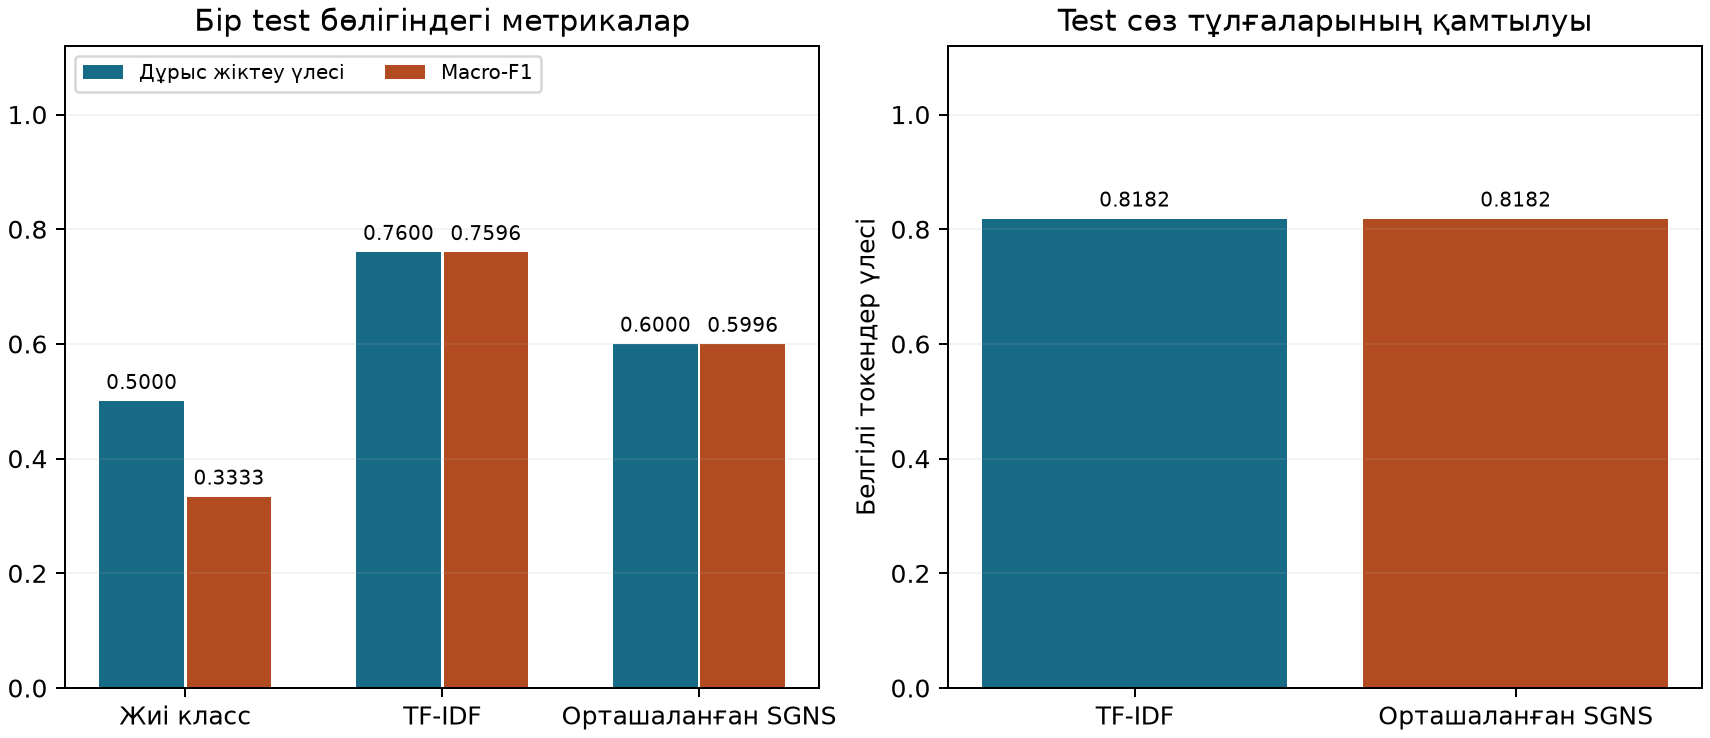

In [6]:
def evaluate_holdout(data, tfidf, pooled, vocab):
    tokens, y, train, test = (data[key] for key in ("tokens", "y", "train", "test"))
    dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(train), 1)), y[train])
    predicted = {"Majority": dummy.predict(np.zeros((len(test), 1))),
                 "TF-IDF": tfidf[0], "SGNS pooled": pooled[0]}
    rows = [{"model": name, "accuracy": float(accuracy_score(y[test], values)),
             "macro_F1": float(f1_score(y[test], values, labels=[0, 1], average="macro", zero_division=0)),
             "confusion_0_1": confusion_matrix(y[test], values, labels=[0, 1]).tolist()}
            for name, values in predicted.items()]
    token_total = sum(len(tokens[index]) for index in test)
    coverage = []
    for name, words, columns, zero_rows in (("TF-IDF", tfidf[1], tfidf[3], tfidf[2]),
                                             ("SGNS pooled", vocab, DIM, pooled[1])):
        token_known = sum(word in words for index in test for word in tokens[index])
        coverage.append({"representation": name, "train_unigrams": len(words), "vector_columns": columns,
                         "test_token_count": token_total, "test_known_tokens": token_known,
                         "test_token_coverage": token_known / token_total,
                         "zero_test_rows": int(zero_rows.sum()),
                         "zero_test_row_ids": data["row_ids"][test[zero_rows]].tolist()})
    tfidf_wrong = predicted["TF-IDF"] != y[test]
    pooled_wrong = predicted["SGNS pooled"] != y[test]
    error_groups = {"both_correct": int((~tfidf_wrong & ~pooled_wrong).sum()),
                    "only_tfidf_wrong": int((tfidf_wrong & ~pooled_wrong).sum()),
                    "only_sgns_wrong": int((~tfidf_wrong & pooled_wrong).sum()),
                    "both_wrong": int((tfidf_wrong & pooled_wrong).sum())}
    print(pd.DataFrame(rows).to_string(index=False))
    print(pd.DataFrame(coverage).drop(columns="zero_test_row_ids").to_string(index=False))
    print("Holdout жұптық нәтижелері:", error_groups)
    return {"metrics": rows, "coverage": coverage, "error_groups": error_groups,
            "train_row_ids": data["row_ids"][train].tolist(), "test_row_ids": data["row_ids"][test].tolist(),
            "test_y": y[test].tolist(), "predictions": {name: values.tolist() for name, values in predicted.items()}}


def plot_representations(evaluation, path):
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.1), layout="constrained")
    names = [row["model"].replace("Majority", "Жиі класс").replace("SGNS pooled", "Орташаланған SGNS") for row in evaluation["metrics"]]
    positions = np.arange(len(names))
    for offset, key, label, color in ((-.17, "accuracy", "Дұрыс жіктеу үлесі", "#176B87"),
                                       (.17, "macro_F1", "Macro-F1", "#B34B20")):
        bars = axes[0].bar(positions + offset, [row[key] for row in evaluation["metrics"]],
                           width=.33, label=label, color=color)
        axes[0].bar_label(bars, fmt="%.4f", fontsize=8, padding=3)
    axes[0].set(xticks=positions, xticklabels=names, ylim=(0, 1.12), title="Бір test бөлігіндегі метрикалар")
    axes[0].legend(ncols=2, loc="upper left", fontsize=8)
    coverage = evaluation["coverage"]
    bars = axes[1].bar([row["representation"].replace("SGNS pooled", "Орташаланған SGNS") for row in coverage],
                       [row["test_token_coverage"] for row in coverage], color=["#176B87", "#B34B20"])
    axes[1].bar_label(bars, fmt="%.4f", fontsize=8, padding=3)
    axes[1].set(ylim=(0, 1.12), title="Test сөз тұлғаларының қамтылуы", ylabel="Белгілі токендер үлесі")
    for axis in axes:
        axis.grid(axis="y", alpha=.14)
    fig.savefig(path, dpi=180)
    plt.close(fig)


evaluation = evaluate_holdout(data, tfidf, pooled, vocab)
plot_representations(evaluation, FIGURES / "ch12_05_representation_comparison.png")
display(Image(filename=str(FIGURES / "ch12_05_representation_comparison.png")))


### Екі диагностика

Сол жақта контекст шығыны train бөлігінде өлшенеді. Оң жақта әр тест жолы үшін қай модель белгіні дұрыс тапқаны ескеріледі. Төрт нәтиженің қосындысы test өлшеміне тең.


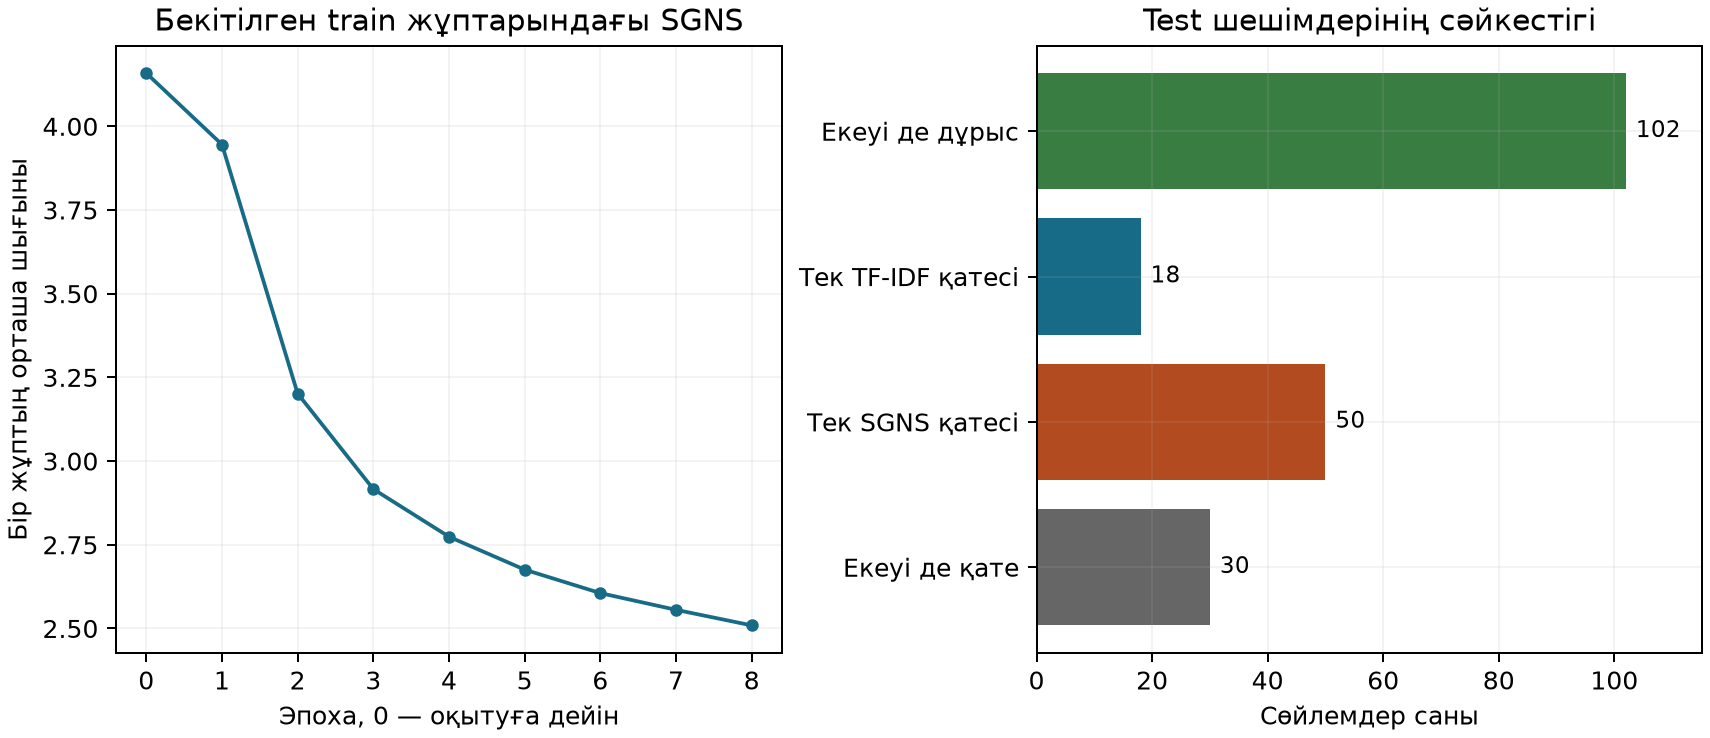

In [7]:
def plot_diagnostics(training, evaluation, path):
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.1), layout="constrained")
    losses = training["fixed_train_loss_per_pair"]
    axes[0].plot(range(len(losses)), losses, marker="o", markersize=4, color="#176B87")
    axes[0].set(xticks=range(len(losses)), title="Бекітілген train жұптарындағы SGNS",
                xlabel="Эпоха, 0 — оқытуға дейін", ylabel="Бір жұптың орташа шығыны")
    keys = ["both_correct", "only_tfidf_wrong", "only_sgns_wrong", "both_wrong"]
    labels = ["Екеуі де дұрыс", "Тек TF-IDF қатесі", "Тек SGNS қатесі", "Екеуі де қате"]
    bars = axes[1].barh(labels, [evaluation["error_groups"][key] for key in keys],
                        color=["#3A7D43", "#176B87", "#B34B20", "#666666"])
    axes[1].bar_label(bars, fmt="%d", fontsize=9, padding=4)
    axes[1].invert_yaxis()
    axes[1].margins(x=.13)
    axes[1].set(title="Test шешімдерінің сәйкестігі", xlabel="Сөйлемдер саны")
    for axis in axes:
        axis.grid(alpha=.14)
    fig.savefig(path, dpi=180)
    plt.close(fig)


plot_diagnostics(training, evaluation, FIGURES / "ch12_06_sgns_diagnostics.png")
display(Image(filename=str(FIGURES / "ch12_06_sgns_diagnostics.png")))


**Сіздің жауабыңыз.** Диаграммадан TF-IDF дұрыс жауаптарының санын қалпына келтіріңіз. Сөздік өлшемдері әртүрлі болғанда қамтудың сәйкес келуін түсіндіріңіз.

_Өз қорытындыңызды жазыңыз._


### 10-қадам. Экспорт және өзін-өзі тексеру

Индекстерді, векторлар өлшемін, градиент дәлдігін, қамтуды және test пайдалану шекарасын тексереміз. JSON болжамдарды бастапқы нөмірлеумен сақтайды.


In [8]:
def save_results(source, data, gradient, training, evaluation, path):
    result = {"source": source, "grouping_and_split": data["summary"], "gradient_check": gradient,
              "sgns_training": training, "evaluation": evaluation,
              "feature_fit_on_train_only": True, "test_used_for_tuning": False,
              "runtime": {"Python": platform.python_version(), "device": "CPU",
                          "packages": {name: version(name) for name in PACKAGES},
                          "threadpoolctl_limit": 1,
                          "thread_environment": {name: os.getenv(name) for name in THREAD_ENVIRONMENT}}}
    path.write_text(json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return result


result = save_results(source, data, gradient, training, evaluation, ROOT / "lab12_results.json")
train, test = set(evaluation["train_row_ids"]), set(evaluation["test_row_ids"])
assert len(train) == 800 and len(test) == 200 and not train & test
assert train | test == set(range(1000))
assert data["summary"]["group_overlap"] == 0
assert inputs.shape == (len(vocab), 32)
assert sum(evaluation["error_groups"].values()) == len(test)
assert max(gradient["max_abs_error_inputs"], gradient["max_abs_error_outputs"]) < gradient["absolute_tolerance"]
assert not result["test_used_for_tuning"]
print("Индекстер, градиент, қамту және нәтижелер тексерілді.")


Индекстер, градиент, қамту және нәтижелер тексерілді.


### Жеке нұсқа және қорғау

Салыстыруларды сол топтастырумен тек train ішкі фолдтарында жүргізіңіз.

1. Униграммалар және униграммалар мен биграммалар.
2. min_df шегінің 2 және 4 мәндері.
3. SGNS өлшемдерінің 16 және 32 мәндері.
4. Радиустары 1 және 2 терезелер.
5. Кәдімгі орташа және IDF салмақтары бар орташа.
6. Болымсыздығы және сөз реті өзгертілген синтетикалық сөйлемдерді салыстыру.

Жергілікті рубрика 100% құрайды. Деректер мен бөлу 15%, токенизация 15%, TF-IDF 20%, SGNS 20%, метрикалар мен қамту 15%, есеп және қайталанымдылық 15% береді. Силлабус бөлек 7 ресми балл көрсетеді.

1. Мәтіннің қандай нұсқаларының кілті бірдей?
2. Болымсыздық қалай сақталады?
3. IDF қандай жолдарда есептеледі?
4. min_df және min_count нені санайды?
5. Оң жұптар қалай құрылады?
6. Қайталанатын индекстер градиенттері қалай жинақталады?
7. Ақырлы айырымдармен тексеру қалай жұмыс істейді?
8. Толық OOV мәтінмен не болады?
9. Жұптық салыстыруға қандай нәтижелер кіреді?
10. Қамтудың сәйкес келуі әртүрлі macro-F1 мәндерімен неліктен үйлеседі?
